# Inside a neural network: customer churn
Run all cells from a fresh kernel. This notebook uses the same model and training implementation as the Streamlit demo.

**Learning goals:** explain a neuron; connect the forward pass to code; distinguish gradients from updates; evaluate predictions on unseen rows.

We use four numeric inputs, two hidden layers (8 and 4 neurons), and a sigmoid output. The target is Churn: 0 = stayed, 1 = left. Dataset units and provenance are not inferred from column names.

In [1]:
from pathlib import Path
import sys
import inspect
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report

ROOT = Path.cwd()
if not (ROOT / "src/neural_networks").exists():
    ROOT = ROOT.parent
assert (ROOT / "src/neural_networks").exists(), "Run from the project root or notebooks directory."
sys.path.insert(0, str(ROOT / "src"))
from neural_networks.model import ChurnNN, FEATURES
from neural_networks.train import clean_data, run_training, evaluate


## 1. Clean first, then construct features and labels
The original notebook created X/y before cleaning df. That leaves stale missing values in X/y. The shared cleaner handles missing/non-numeric/infinite values and removes exact duplicate selected-feature/label rows before splitting.

In [2]:
data, cleaning = clean_data(ROOT / "data/train.csv")
print(cleaning)
display(data.head())
display(data.Churn.value_counts(normalize=True).rename("proportion"))
X = data[FEATURES]
y = data["Churn"]
assert X.notna().all().all() and y.notna().all()


{'raw_rows': 440833, 'invalid_rows_removed': 1, 'duplicate_rows_removed': 2208, 'clean_rows': 438624}


,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
0,5.0,18.0,932.0,17.0,1.0
1,10.0,8.0,557.0,6.0,1.0
2,6.0,18.0,185.0,3.0,1.0
3,7.0,7.0,396.0,29.0,1.0
4,5.0,8.0,617.0,20.0,1.0


Churn
1.0    0.565211
0.0    0.434789
Name: proportion, dtype: float64

## 2. One neuron → a network
A neuron calculates a weighted sum plus bias and then an activation. ReLU is max(0, z). The final Sigmoid converts its score into an estimated probability. The threshold converts the probability to a class.

Our 4 → 8 → 4 → 1 model has (4×8+8) + (8×4+4) + (4×1+1) = **81 parameters**. Hidden neurons need not correspond to named human concepts.

In [3]:
print(inspect.getsource(ChurnNN))
print("Trainable parameters:", sum(p.numel() for p in ChurnNN().parameters()))


class ChurnNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(4, 8)
        self.layer2 = nn.Linear(8, 4)
        self.output = nn.Linear(4, 1)
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.relu(self.layer1(x))
        x = self.relu(self.layer2(x))
        return self.sigmoid(self.output(x))

    def inspect(self, x):
        """Return actual intermediate values for the educational frontend."""
        with torch.no_grad():
            z1 = self.layer1(x)
            a1 = self.relu(z1)
            z2 = self.layer2(a1)
            a2 = self.relu(z2)
            z3 = self.output(a2)
            p = self.sigmoid(z3)
        return {k: v.cpu().numpy()[0] for k, v in
                dict(inputs=x, z1=z1, a1=a1, z2=z2, a2=a2, z3=z3, probability=p).items()}

Trainable parameters: 81


## 3. Read the training implementation
First split rows into training (64%), validation (16%), and holdout (20%). Fit scaling on training only. For every batch: forward → loss → backward → update. BCELoss matches this model's explicit Sigmoid.

Backpropagation calculates gradients. Adam changes weights. Validation selects the checkpoint; the holdout does not participate in that choice. The batch losses are weighted by row count before averaging.

In [4]:
print(inspect.getsource(run_training))

def run_training(data_path=None, output_dir=None, epochs=20, batch_size=512, seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.set_num_threads(2)
    data_path = Path(data_path or ROOT / "data/train.csv")
    output_dir = Path(output_dir or ROOT / "artifacts")
    output_dir.mkdir(parents=True, exist_ok=True)
    data, cleaning = clean_data(data_path)
    trainval, test = train_test_split(data, test_size=0.2, stratify=data.Churn, random_state=seed)
    train, val = train_test_split(trainval, test_size=0.2, stratify=trainval.Churn, random_state=seed)
    scaler = StandardScaler().fit(train[FEATURES])

    def tensors(frame):
        return (torch.tensor(scaler.transform(frame[FEATURES]), dtype=torch.float32),
                torch.tensor(frame.Churn.to_numpy(), dtype=torch.float32).reshape(-1, 1))

    x_train, y_train = tensors(train)
    x_val, y_val = tensors(val)
    x_test, y_test = tensors(test)
    loader = DataLoader(TensorDataset(x_train, y_train), batch_

## 4. Train from a fresh initialization
This call resets the seed, model, optimizer, and history together. Re-running this cell starts a fresh run. It exports a matched model/scaler/results bundle for the frontend. Training may take a few minutes on CPU.

In [5]:
model, metadata, history, metrics = run_training(
    data_path=ROOT / "data/train.csv",
    output_dir=ROOT / "artifacts",
    epochs=20, batch_size=512, seed=42,
)
print("Selected epoch:", metadata["best_epoch"])
print("Split sizes:", metadata["splits"])


Epoch 01/20: train=0.5022 validation=0.3361
Epoch 02/20: train=0.2996 validation=0.2743
Epoch 03/20: train=0.2629 validation=0.2525
Epoch 04/20: train=0.2453 validation=0.2402
Epoch 05/20: train=0.2363 validation=0.2337
Epoch 06/20: train=0.2309 validation=0.2296
Epoch 07/20: train=0.2271 validation=0.2264
Epoch 08/20: train=0.2244 validation=0.2242
Epoch 09/20: train=0.2225 validation=0.2225
Epoch 10/20: train=0.2210 validation=0.2213
Epoch 11/20: train=0.2198 validation=0.2203
Epoch 12/20: train=0.2187 validation=0.2192
Epoch 13/20: train=0.2176 validation=0.2180
Epoch 14/20: train=0.2167 validation=0.2172
Epoch 15/20: train=0.2160 validation=0.2166
Epoch 16/20: train=0.2153 validation=0.2158
Epoch 17/20: train=0.2148 validation=0.2157
Epoch 18/20: train=0.2143 validation=0.2150
Epoch 19/20: train=0.2139 validation=0.2147
Epoch 20/20: train=0.2136 validation=0.2144
{
  "neural_network": {
    "rows": 87725,
    "churn_rate": 0.5652094613850099,
    "threshold": 0.5,
    "accuracy": 0

## 5. Plot learning
There is exactly one history record per epoch. Training loss reflects changing weights across batches; validation loss uses the end-of-epoch model. Lower training loss alone does not establish generalization.

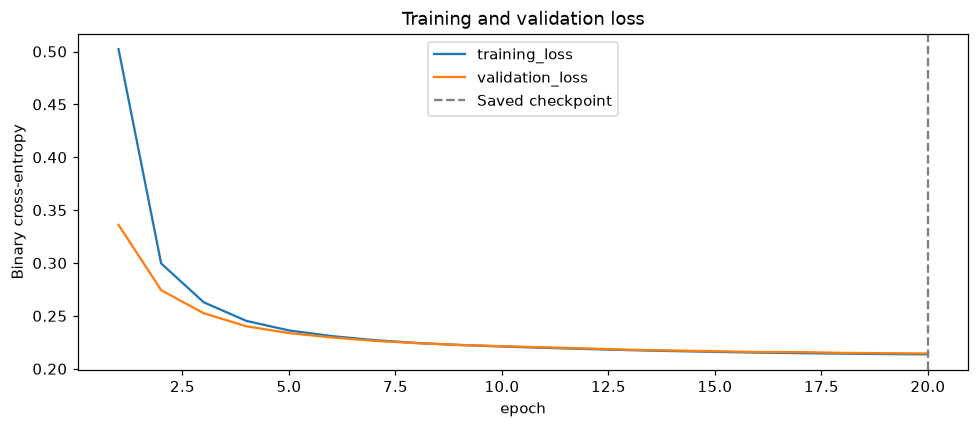

In [6]:
history_frame = pd.DataFrame(history).set_index("epoch")
assert len(history_frame) == metadata["epochs"]
history_frame.plot(figsize=(9, 4), ylabel="Binary cross-entropy", title="Training and validation loss")
plt.axvline(metadata["best_epoch"], color="gray", linestyle="--", label="Saved checkpoint")
plt.legend()
plt.tight_layout()
plt.show()


## 6. Independently reproduce holdout predictions
Load the saved weights and preprocessing statistics. eval() sets evaluation behavior; no_grad() disables gradient tracking. Neither updates parameters. Compare the recomputed probabilities with the exported evaluation predictions.

In [7]:
holdout = pd.read_csv(ROOT / "artifacts/holdout_predictions.csv")
saved_model = ChurnNN()
saved_model.load_state_dict(torch.load(ROOT / "artifacts/model.pt", map_location="cpu", weights_only=True))
saved_model.eval()
scaled = (holdout[FEATURES].to_numpy() - np.array(metadata["scaler_mean"])) / np.array(metadata["scaler_scale"])
with torch.no_grad():
    probabilities = saved_model(torch.tensor(scaled, dtype=torch.float32)).numpy().ravel()
np.testing.assert_allclose(probabilities, holdout.probability, atol=1e-6)
predictions = (probabilities >= 0.5).astype(int)
print(classification_report(holdout.Churn, predictions, target_names=["Stay", "Churn"], zero_division=0))
display(pd.DataFrame({name: {key: value for key, value in result.items() if key in
    ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision", "log_loss"]}
    for name, result in metrics.items()}).T)


              precision    recall  f1-score   support

        Stay       0.85      0.99      0.92     38142
       Churn       0.99      0.86      0.92     49583

    accuracy                           0.92     87725
   macro avg       0.92      0.93      0.92     87725
weighted avg       0.93      0.92      0.92     87725



,accuracy,precision,recall,f1,roc_auc,average_precision,log_loss
neural_network,0.920217,0.993556,0.864450,0.924517,0.953429,0.973533,0.213862
logistic_regression,0.840034,0.872407,0.839804,0.855795,0.915669,0.947256,0.355446
majority_baseline,0.565209,0.565209,1.000000,0.722216,0.500000,0.565209,0.684618
external_test_file,0.586853,0.534160,0.989157,0.693707,0.652556,0.566372,5.667406
external_logistic_regression,0.588351,0.535720,0.972454,0.690853,0.762632,0.716442,1.344511


## 7. Inspect errors and compare baselines
Precision: among predicted churners, how many actually churned? Recall: among actual churners, how many were identified? False positives are false alarms; false negatives are missed churners.

Logistic regression and the majority baseline use the same internal holdout. Neural networks are not automatically superior. Separate test.csv results are reported separately because its sampling/provenance is not established.

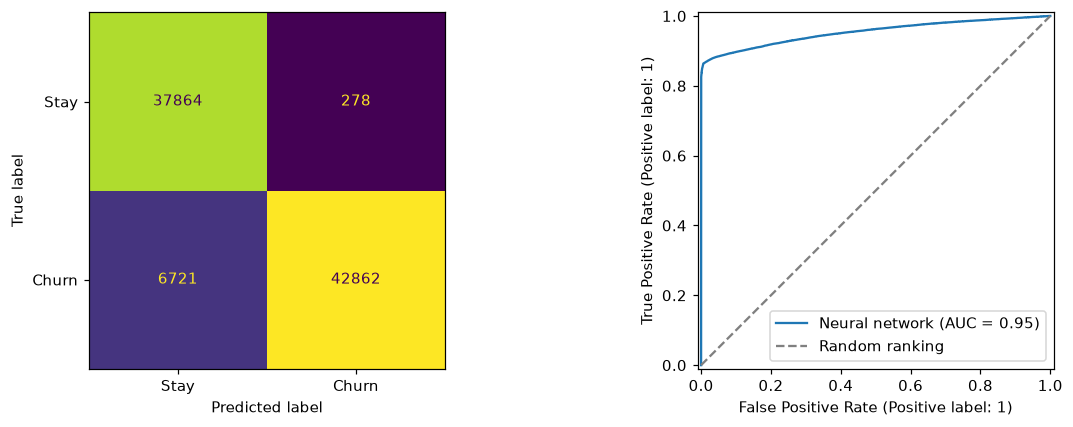

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(holdout.Churn, predictions, display_labels=["Stay", "Churn"], ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(holdout.Churn, probabilities, ax=axes[1], name="Neural network")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
axes[1].legend()
plt.tight_layout()
plt.show()


## 8. Follow one customer through every layer
These are actual model activations. The same inspect() method powers the frontend. Altering a feature shows the model's response, not a causal effect on churn.

In [9]:
customer = holdout[FEATURES].iloc[0]
display(customer)
network_input = (customer.to_numpy() - np.array(metadata["scaler_mean"])) / np.array(metadata["scaler_scale"])
trace = saved_model.inspect(torch.tensor(network_input, dtype=torch.float32).reshape(1, 4))
for stage, values in trace.items():
    print(stage, np.round(values, 4))


inputs [-0.8469 -0.5999 -1.9929 -0.7534]
z1 [-2.1085  3.2149 -1.6884 -2.675   1.3448  2.1759  0.4458  1.579 ]
a1 [0.     3.2149 0.     0.     1.3448 2.1759 0.4458 1.579 ]
z2 [-2.3876  8.0017 13.9048  8.5755]
a2 [ 0.      8.0017 13.9048  8.5755]
z3 [114.402]
probability [1.]


Support Calls         1.0
Payment Delay         8.0
Total Spend         153.0
Last Interaction      8.0
Name: 0, dtype: float64

## 9. Present the interactive demo
From the project root: `python -m streamlit run src/neural_networks/app.py`.

Use LESSON.md for the presentation flow. The model is a teaching example: probability calibration, dataset provenance, customer/time independence, and intervention effectiveness are not established. Earlier feature exploration also used the source dataset. For a stronger final study, freeze decisions before collecting an independent test set.